# Лабораторная работа № 3
**Тема:** Декомпозиция и сглаживание временных рядов

**Цель:** сравнить классическую декомпозицию, STL и MSTL на ряду с двумя сезонностями

**Задачи:** генерация данных функцией из лабораторной №1; сглаживание SMA/EMA; визуальный анализ, суточные и недельные профили; ACF; декомпозиция тремя методами; сравнение дисперсии и ACF остатков; выводы

## 1. Импорт библиотек и оформление
Потребуются NumPy, pandas, Matplotlib и statsmodels (версия не ниже 0.14 для MSTL)

In [1]:
from datetime import datetime, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf

OUT = Path('images'); OUT.mkdir(exist_ok=True)
PURPLE = '#7C3AED'; DARK = '#5B21B6'; LILAC = '#A78BFA'; PINK = '#C084FC'; LIGHT = '#DDD6FE'
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.2})
def save(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

## 2. Генератор из первой лабораторной
Ниже вставлена ***исходная функция без изменения*** её математической логики. Она всегда создаёт ряд с шагом пять минут. Сезонности первой лабораторной имеют периоды 1 и 6 часов. Для этой практики нужна суточная и недельная сезонность, поэтому добавим их после создания ряда, не изменяя генератор

In [2]:
"""Возвращает метки времени, значения ряда и выбранные режимы"""
def generate_time_series(n_points=1000, volatility="random", trend="random",
                         seasonality="random", seed=None):
    if not isinstance(n_points, (int, np.integer)) or isinstance(n_points, (bool, np.bool_)) or n_points <= 0:
        raise ValueError("n_points должно быть положительным целым числом")

    volatility_modes = ("const", "grow", "decay")
    trend_modes = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
    seasonality_modes = ("none", "one", "two")

    for label, option, modes in (
        ("volatility", volatility, volatility_modes),
        ("trend", trend, trend_modes),
        ("seasonality", seasonality, seasonality_modes),
    ):
        if option not in (*modes, "random"):
            raise ValueError(f"Недопустимое значение {label}: {option}. Допустимые: {(*modes, 'random')}")

    rng = np.random.default_rng(seed)
    if volatility == "random":
        volatility = str(rng.choice(volatility_modes))
    if trend == "random":
        trend = str(rng.choice(trend_modes))
    if seasonality == "random":
        seasonality = str(rng.choice(seasonality_modes))

    start_time = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start_time + timedelta(minutes=5 * i) for i in range(n_points)]

    t = np.arange(n_points)
    position = t / max(n_points - 1, 1)  # от 0 до 1 на протяжении ряда

    # Тренд: изменения за весь наблюдаемый отрезок
    total_changes = {"none": 0, "fast_up": 35, "slow_up": 10,
                     "fast_down": -35, "slow_down": -10}
    trend_values = total_changes[trend] * position

    # Сезонность: периоды 12 точек (1 час) и 72 точки (6 часов)
    seasonal_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        seasonal_values += 7 * np.sin(2 * np.pi * t / 12)
    if seasonality == "two":
        seasonal_values += 4 * np.sin(2 * np.pi * t / 72)

    # Стандартное отклонение задаёт силу шума; дисперсия равна его квадрату
    if volatility == "const":
        sigma = np.full(n_points, 2.0)
    elif volatility == "grow":
        sigma = 1.0 + 6.0 * position
    else:  # decay
        sigma = 7.0 - 6.0 * position

    noise = rng.normal(loc=0.0, scale=sigma, size=n_points)
    values = 100.0 + trend_values + seasonal_values + noise
    modes = {"volatility": volatility, "trend": trend, "seasonality": seasonality}
    return timestamps, values, modes

## 3. Создание почасового ряда
Генерируем *6 недель пятиминутных значений* с постоянной дисперсией и медленным ростом. Усредняем каждые 12 точек: получаем 1008 почасовых наблюдений. Затем добавляем суточный период 24 часа, недельный период 168 часов, небольшой сдвиг уровня и восемь выбросов. Амплитуды не зависят от уровня, поэтому выбираем аддитивную модель

In [3]:
HOURS = 24 * 7 * 6
raw_times, raw_values, modes = generate_time_series(n_points=HOURS*12, volatility='const', trend='slow_up', seasonality='none', seed=42)
index = pd.DatetimeIndex(raw_times[::12], name='timestamp')
t = np.arange(HOURS)
base = raw_values.reshape(HOURS, 12).mean(axis=1)
daily = 9*np.sin(2*np.pi*t/24) + 2*np.cos(2*np.pi*t/24)
weekly = 14*np.sin(2*np.pi*t/168) + 3*np.cos(2*np.pi*t/168)
values = base + daily + weekly + np.where(t>=HOURS//2, 3.0, 0.0)
rng = np.random.default_rng(2026)
outliers = np.sort(rng.choice(np.arange(36,HOURS-36), 8, replace=False))
values[outliers] += rng.choice([-1,1],8)*rng.uniform(18,27,8)
series = pd.Series(values, index=index, name='value')
series.to_frame().to_csv('series.csv', index_label='timestamp', float_format='%.6f')
assert len(series)==1008 and series.index.is_unique
assert (series.index.to_series().diff().dropna()==pd.Timedelta(hours=1)).all()
print('Количество точек:',len(series),'Шаг:',series.index[1]-series.index[0]);print(series.head().round(2))

Количество точек: 1008 Шаг: 0 days 01:00:00
timestamp
2026-11-08 00:00:00    104.72
2026-11-08 01:00:00    108.00
2026-11-08 02:00:00    110.81
2026-11-08 03:00:00    112.55
2026-11-08 04:00:00    113.91
Name: value, dtype: float64


## 4. Визуальный анализ
Смотрим весь ряд и увеличенный фрагмент, средние суточные и недельные подсерии, тепловую карту «час x день недели». Ряд содержит как 24-часовую, так и 168-часовую периодичность

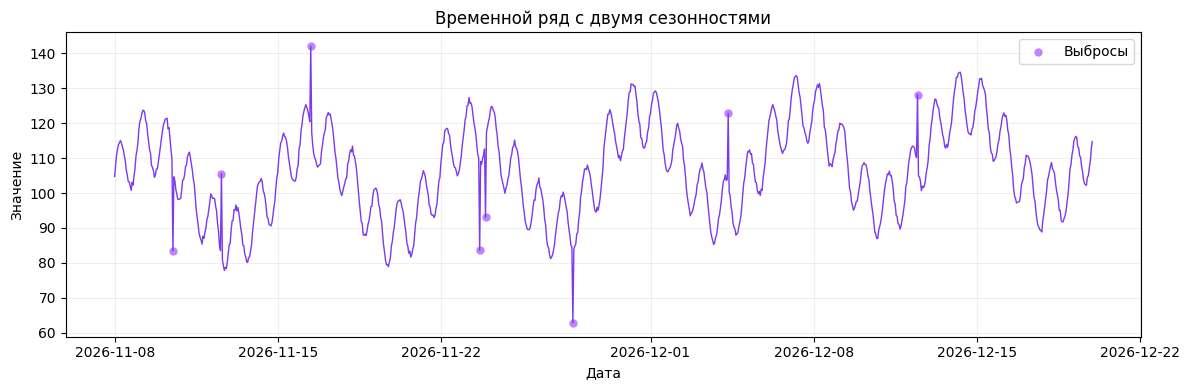

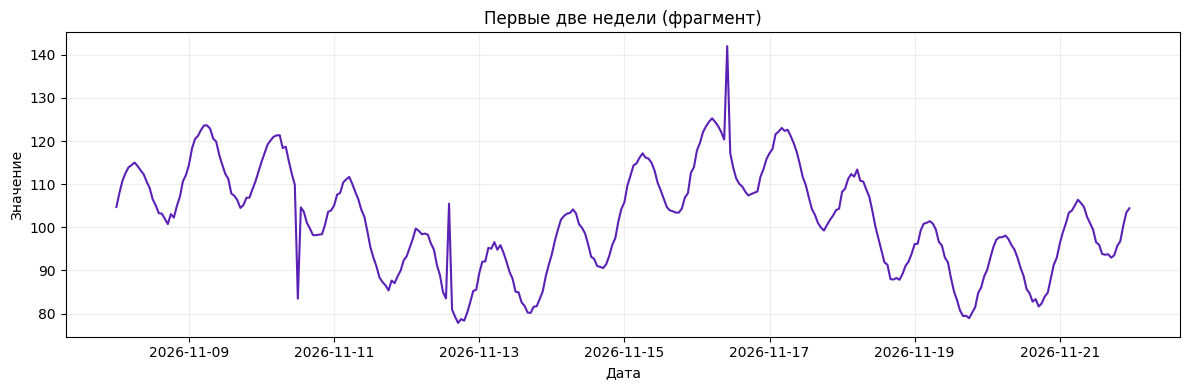

In [4]:
plt.figure(figsize=(12,4));plt.plot(series.index,series,color=PURPLE,lw=1)
plt.scatter(series.index[outliers],series.iloc[outliers],c=PINK,s=25,label='Выбросы')
plt.title('Временной ряд с двумя сезонностями');plt.xlabel('Дата');plt.ylabel('Значение');plt.legend();save('lab_image_1.png')
plt.figure(figsize=(12,4));plt.plot(series.index[:336],series.iloc[:336],color=DARK)
plt.title('Первые две недели (фрагмент)');plt.xlabel('Дата');plt.ylabel('Значение');save('lab_image_2.png')

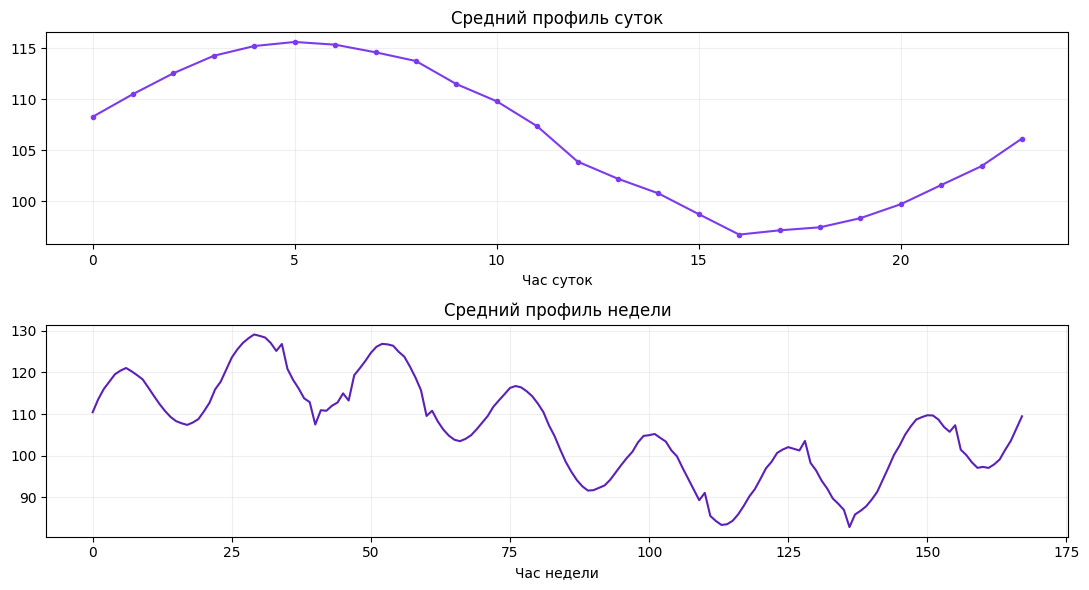

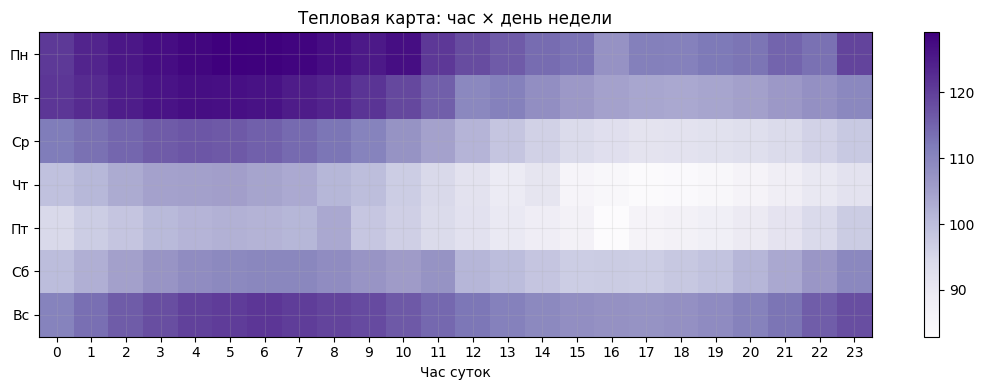

In [5]:
day_profile=series.groupby(series.index.hour).mean()
week_profile=pd.Series(series.to_numpy()).groupby(t%168).mean()
fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(day_profile.index,day_profile,color=PURPLE,marker='o',markersize=3)
axs[0].set_title('Средний профиль суток');axs[0].set_xlabel('Час суток')
axs[1].plot(week_profile.index,week_profile,color=DARK)
axs[1].set_title('Средний профиль недели');axs[1].set_xlabel('Час недели')
save('lab_image_3.png')
heat=series.groupby([series.index.dayofweek,series.index.hour]).mean().unstack()
fig,ax=plt.subplots(figsize=(11,4));im=ax.imshow(heat.values,aspect='auto',cmap='Purples')
ax.set_xticks(np.arange(24));ax.set_yticks(np.arange(7),['Пн','Вт','Ср','Чт','Пт','Сб','Вс']);
ax.set_xlabel('Час суток');ax.set_title('Тепловая карта: час × день недели');fig.colorbar(im,ax=ax);save('lab_image_4.png')

## 5. Сглаживание (SMA и EMA)
**SMA** усредняет последние 24 значения с равными весами. **EMA** придаёт более свежим наблюдениям больший вес

Рассмотрим первые 240 часов

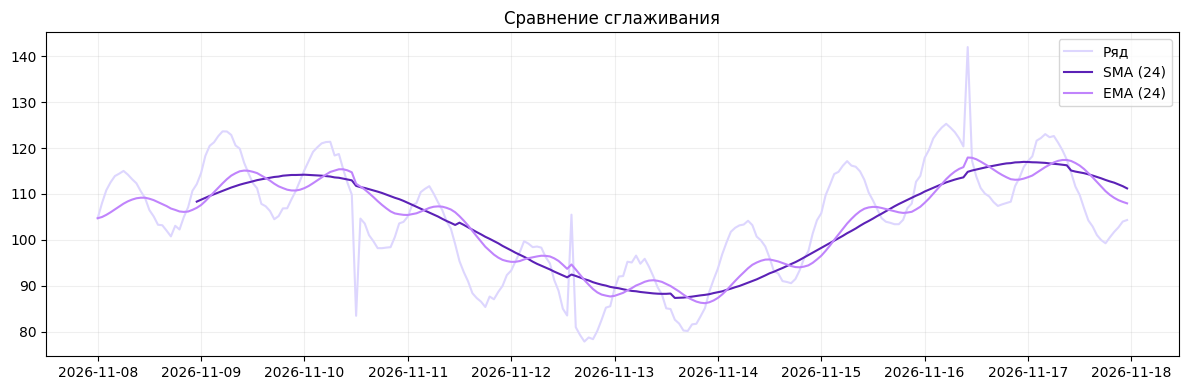

In [6]:
sma=series.rolling(24).mean();ema=series.ewm(span=24,adjust=False).mean()
plt.figure(figsize=(12,4));plt.plot(series.index[:240],series.iloc[:240],color=LIGHT,label='Ряд')
plt.plot(sma.index[:240],sma.iloc[:240],color=DARK,label='SMA (24)')
plt.plot(ema.index[:240],ema.iloc[:240],color=PINK,label='EMA (24)')
plt.title('Сравнение сглаживания');plt.legend();save('lab_image_5.png')

## 6. ACF исходного ряда
Автокорреляция (ACF) сравнивает ряд с его сдвинутой копией. Отмечаем лаги **24** и **168**. Их значения рассматриваем вместе с графиками: тренд и шум могут влиять на форму ACF

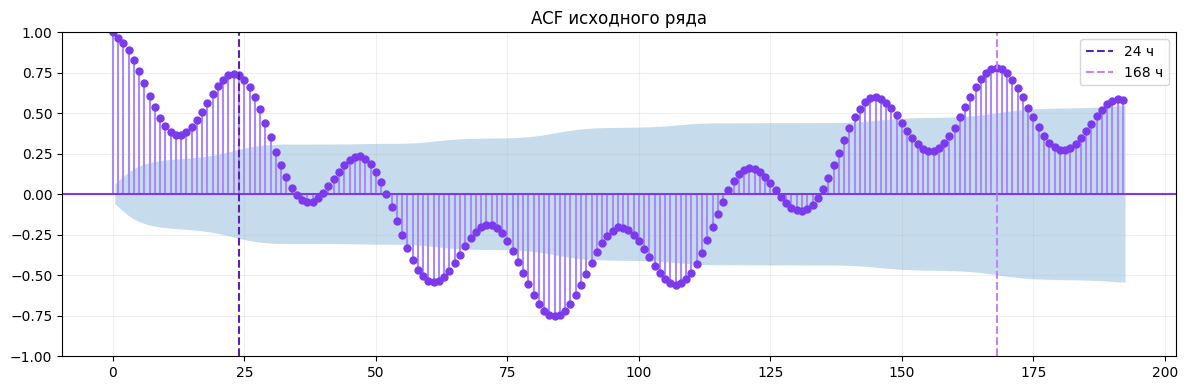

ACF(24): 0.735 ACF(168): 0.779


In [7]:
fig,ax=plt.subplots(figsize=(12,4));plot_acf(series,lags=192,ax=ax,color=PURPLE,vlines_kwargs={'colors':LILAC})
ax.axvline(24,color=DARK,ls='--',label='24 ч');ax.axvline(168,color=PINK,ls='--',label='168 ч')
ax.set_title('ACF исходного ряда');ax.legend();save('lab_image_6.png')
raw_acf=acf(series,nlags=168,fft=True);print('ACF(24):',round(raw_acf[24],3),'ACF(168):',round(raw_acf[168],3))

## 7. Декомпозиция
**Классическая** (period=24) оценивает одну неизменную сезонность. **STL** (period=24, robust=True) допускает изменение сезонности и уменьшает влияние выбросов, но тоже выделяет лишь один период. **MSTL** (periods=(24,168)) оценивает обе сезонности раздельно

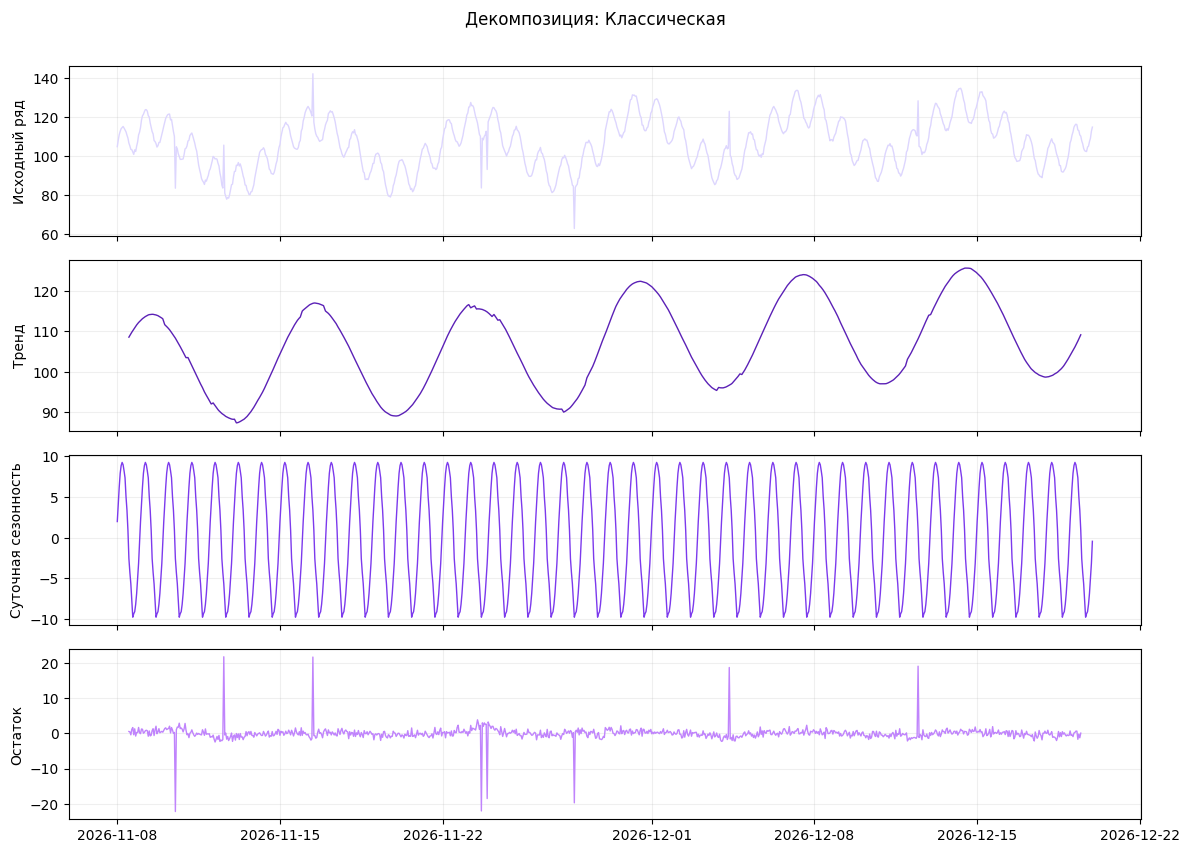

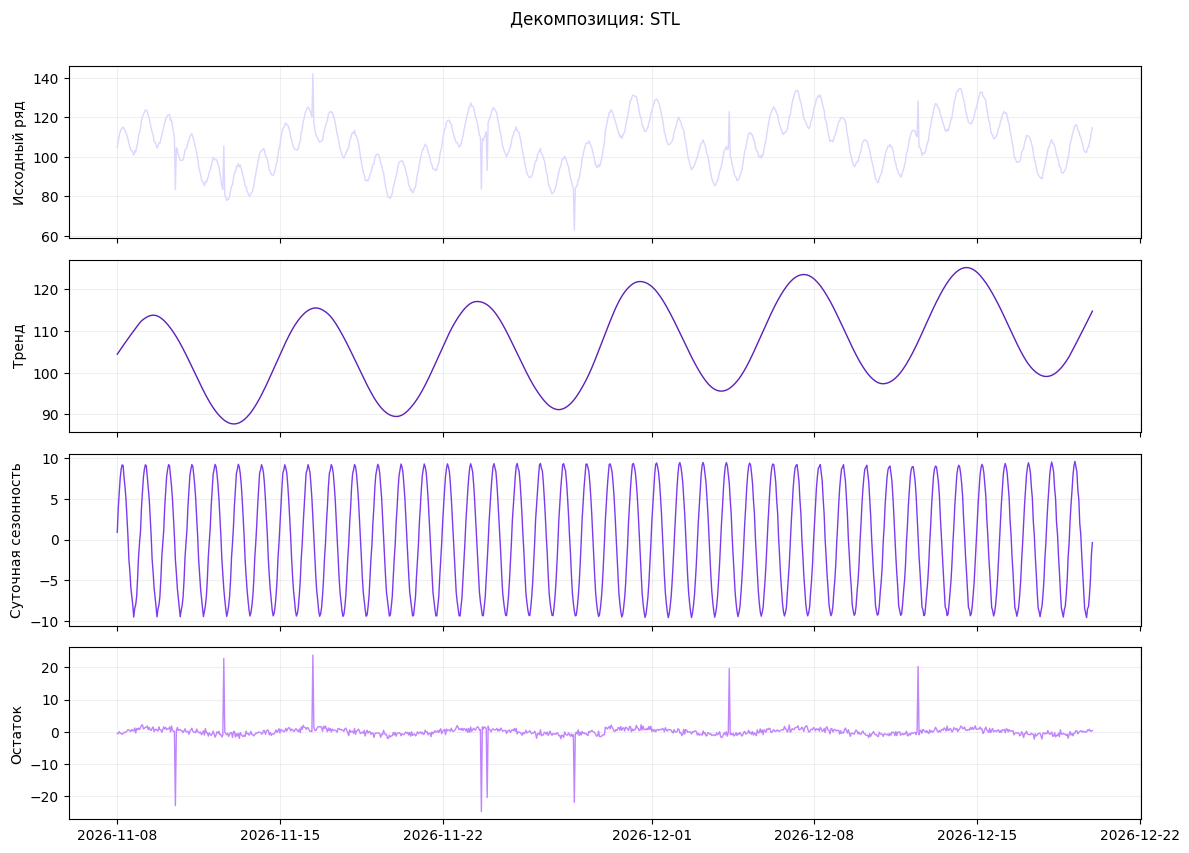

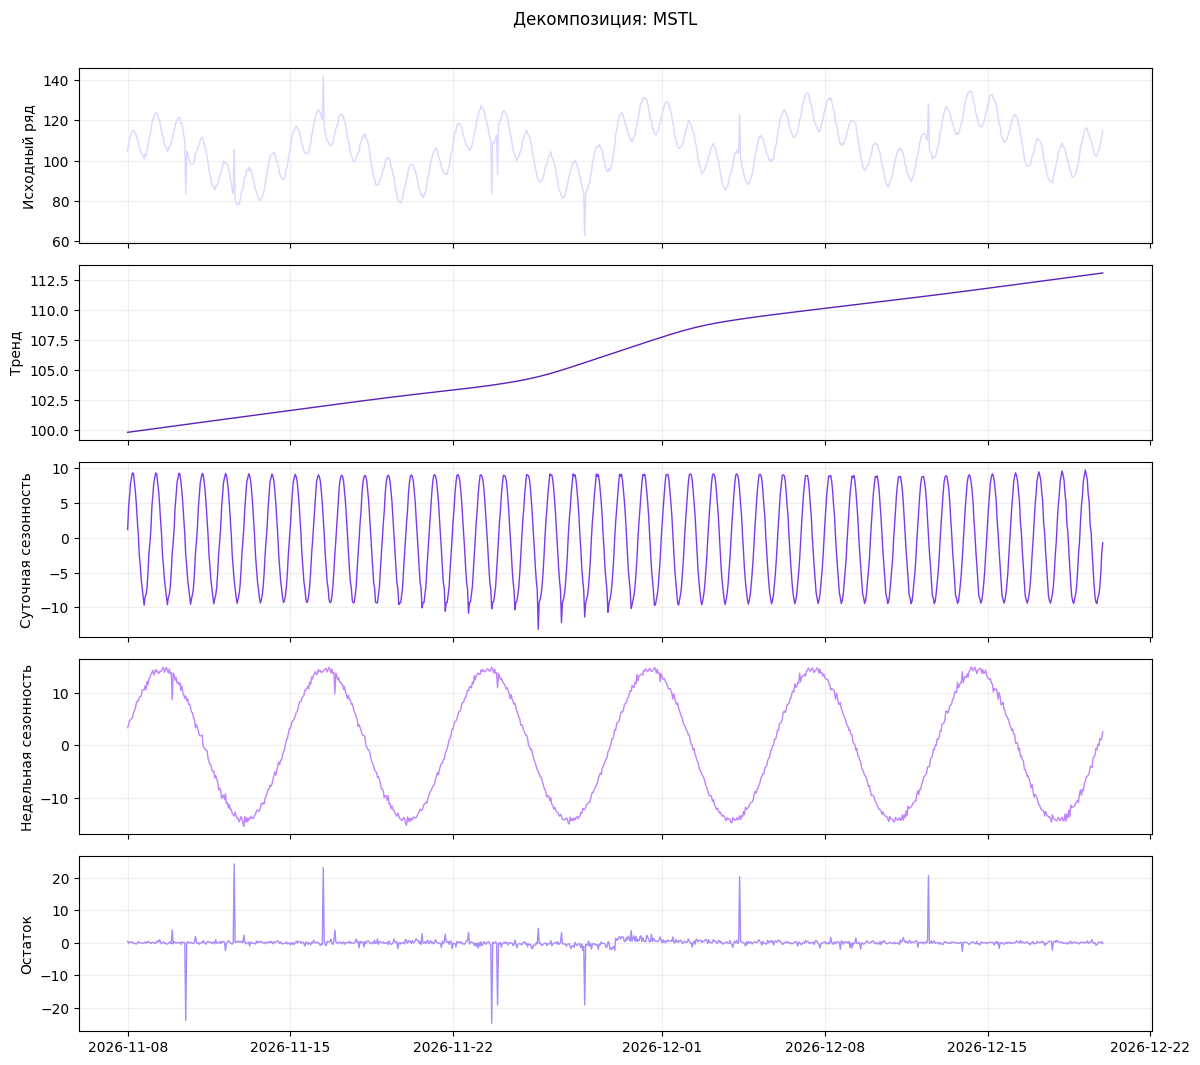

In [13]:

# 1. Классическая декомпозиция
# Выделяем тренд, суточную сезонность и остаток
classical = seasonal_decompose(
    series,
    model="additive",
    period=24
)

# 2. STL-декомпозиция
# robust=True уменьшает влияние выбросов
stl = STL(
    series,
    period=24,
    seasonal=13,
    trend=49,
    robust=True
).fit()

# 3. MSTL-декомпозиция
# Учитываем одновременно суточную и недельную сезонности
mstl = MSTL(
    series,
    periods=(24, 168),
    windows=(13, 15),
    iterate=2,
    stl_kwargs={"robust": True}
).fit()

# Собираем результаты всех методов
parts = {
    "Классическая": {
        "trend": classical.trend,
        "daily": classical.seasonal,
        "resid": classical.resid
    },
    "STL": {
        "trend": stl.trend,
        "daily": stl.seasonal,
        "resid": stl.resid
    },
    "MSTL": {
        "trend": mstl.trend,
        "daily": mstl.seasonal.iloc[:, 0],
        "weekly": mstl.seasonal.iloc[:, 1],
        "resid": mstl.resid
    }
}

# Функция построения графиков компонент
def components_plot(name, comp, filename):

    components = [
        ("Исходный ряд", series),
        ("Тренд", comp["trend"]),
        ("Суточная сезонность", comp["daily"])
    ]

    # Недельная сезонность есть отдельно только у MSTL
    if "weekly" in comp:
        components.append(
            ("Недельная сезонность", comp["weekly"])
        )

    components.append(("Остаток", comp["resid"]))

    # Создаём отдельный график для каждой компоненты
    fig, axes = plt.subplots(
        len(components),
        1,
        figsize=(12, 2.1 * len(components)),
        sharex=True
    )

    colors = [LIGHT, DARK, PURPLE, PINK, LILAC]

    for i, (label, data) in enumerate(components):
        axes[i].plot(
            series.index,
            data,
            color=colors[i],
            linewidth=1
        )
        axes[i].set_ylabel(label)

    fig.suptitle("Декомпозиция: " + name, y=1.01)
    save(filename)


# Строим графики для всех трёх методов
for number, (name, comp) in enumerate(parts.items(), start=7):
    filename = f"lab_image_{number}.png"
    components_plot(name, comp, filename)


## 8. Количественное сравнение
Рассчитываем дисперсию остатков и автокорреляцию при лагах 24 и 168. Чем ниже остаточная дисперсия и чем ближе ACF к нулю, тем меньше необъяснённых колебаний. Одной метрики недостаточно: нужно учитывать интерпретируемость компонент

Сравнение методов декомпозиции:
              Дисперсия  ACF(24)  ACF(168)  Число точек
Метод                                                  
Классическая     4.2473  -0.0030   -0.0006          984
STL              4.6114   0.0293    0.0465         1008
MSTL             4.2844  -0.0114   -0.0486         1008


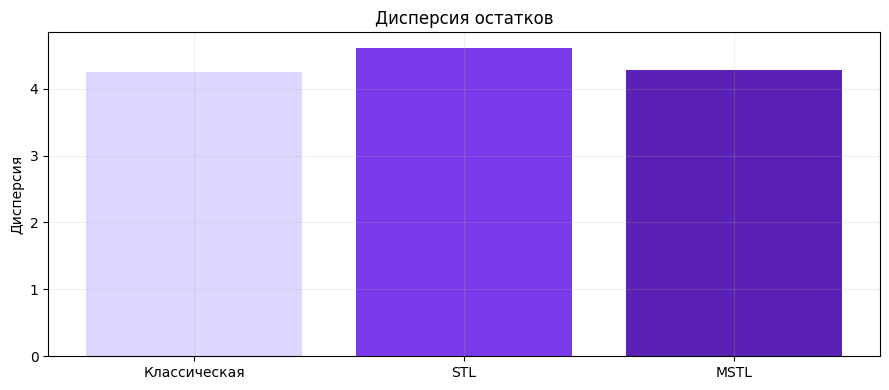

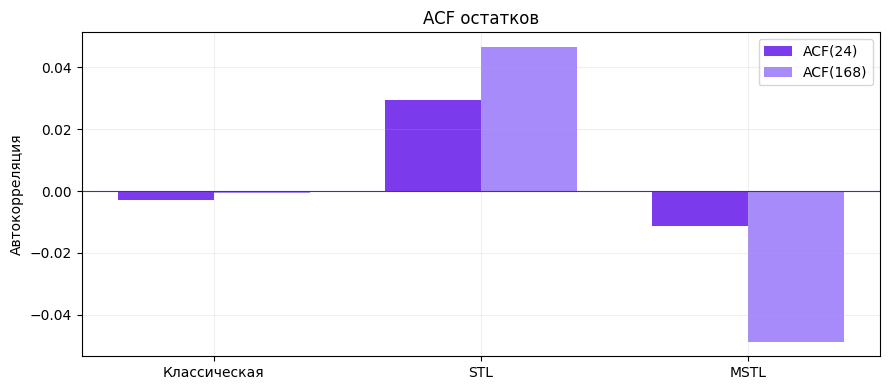

In [14]:

# Список для результатов сравнения
rows = []

for name, comp in parts.items():

    # Получаем остатки и удаляем отсутствующие значения
    residuals = pd.Series(comp["resid"]).dropna()

    # Рассчитываем автокорреляцию
    acf_values = acf(residuals, nlags=168, fft=True)

    # Рассчитываем основные показатели
    variance = residuals.var()
    acf_24 = acf_values[24]
    acf_168 = acf_values[168]

    # Добавляем результаты в таблицу
    rows.append({
        "Метод": name,
        "Дисперсия": variance,
        "ACF(24)": acf_24,
        "ACF(168)": acf_168,
        "Число точек": len(residuals)
    })

# Формируем итоговую таблицу
result = pd.DataFrame(rows)
result = result.set_index("Метод")

# Сохраняем результаты
result.to_csv("comparison.csv", float_format="%.6f")

print("Сравнение методов декомпозиции:")
print(result.round(4).to_string())


# График дисперсии остатков
plt.figure(figsize=(9, 4))

plt.bar(
    result.index,
    result["Дисперсия"],
    color=[LIGHT, PURPLE, DARK]
)

plt.title("Дисперсия остатков")
plt.ylabel("Дисперсия")

save("lab_image_10.png")


# График автокорреляции остатков
x = np.arange(len(result))

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    x - 0.18,
    result["ACF(24)"],
    width=0.36,
    color=PURPLE,
    label="ACF(24)"
)

ax.bar(
    x + 0.18,
    result["ACF(168)"],
    width=0.36,
    color=LILAC,
    label="ACF(168)"
)

ax.axhline(0, color=DARK, linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(result.index)

ax.set_title("ACF остатков")
ax.set_ylabel("Автокорреляция")
ax.legend()

save("lab_image_11.png")


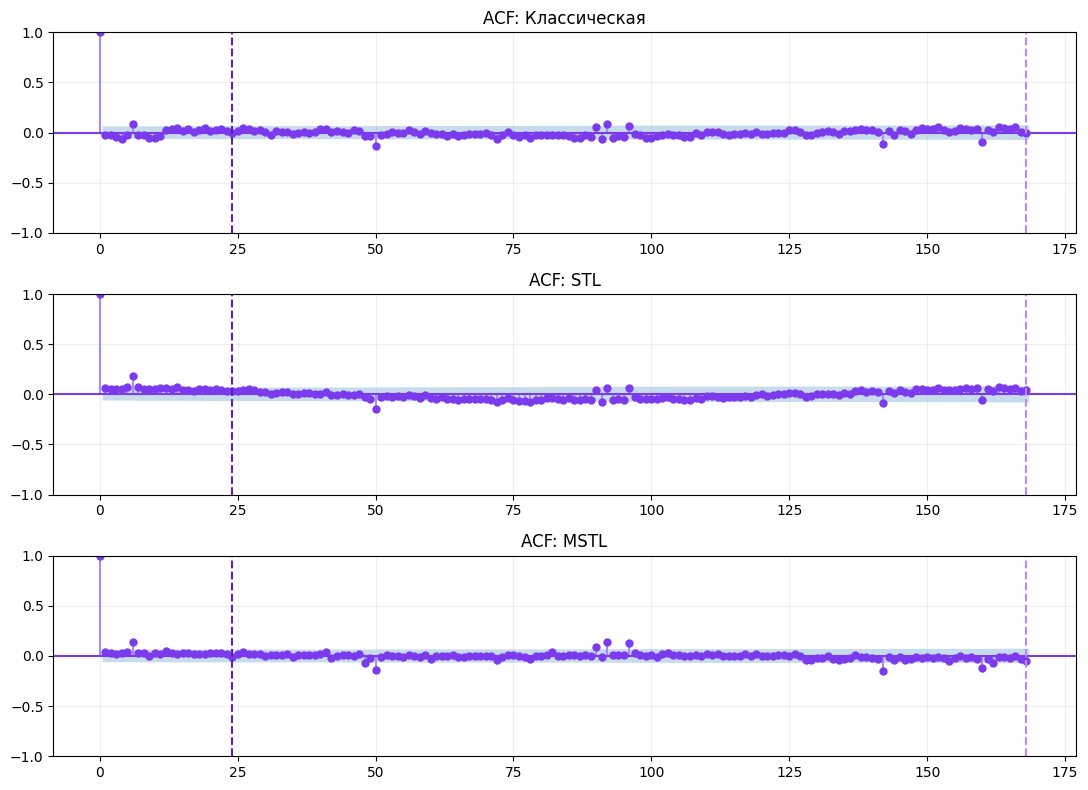

In [10]:
fig,axs=plt.subplots(3,1,figsize=(11,8))
for ax,(name,comp) in zip(axs,parts.items()):
    plot_acf(pd.Series(comp['resid']).dropna(),lags=168,ax=ax,color=PURPLE,vlines_kwargs={'colors':LILAC})
    ax.axvline(24,color=DARK,ls='--');ax.axvline(168,color=PINK,ls='--');ax.set_title('ACF: '+name)
save('lab_image_12.png')

## 9. Обоснование выбранных методов и интерпретация результатов

### 9.1. Почему выбраны периоды 24 и 168?

В данной лабораторной работе рассматривается почасовой временной ряд, содержащий две сезонности: суточную и недельную.

Так как после преобразования данных одно наблюдение соответствует одному часу, периоды определяются следующим образом:

- **24** - количество часов в сутках
- **168** - количество часов в неделе (24 x 7)

Первоначально данные создаются генератором из лабораторной работы № 1 с интервалом 5 минут. Затем каждые 12 последовательных значений усредняются для получения почасового ряда. После этого к данным добавляются две сезонные составляющие с периодами 24 и 168 часов

Выбор этих периодов позволяет исследовать, как разные методы декомпозиции работают с временным рядом, в котором одновременно присутствуют короткие и длинные сезонные колебания

### 9.2. Для чего используется параметр `robust=True`?

Параметр `robust=True` применяется в методах STL и MSTL для уменьшения влияния выбросов на результаты декомпозиции.

В нашем временном ряду специально создаются аномальные значения, которые значительно отличаются от соседних наблюдений. Без робастной обработки такие значения могут искажать оценки тренда и сезонности

При использовании `robust=True` алгоритм уменьшает вес наблюдений с большими отклонениями при оценке компонент. Это позволяет получить более устойчивые оценки тренда и сезонности. При этом выбросы не удаляются из исходного ряда, а их влияние на оценку компонент становится меньше

### 9.3. Чем STL отличается от MSTL?

STL и MSTL используются для разложения временного ряда на тренд, сезонность и случайную составляющую.

Основное отличие заключается *в количестве сезонностей*, которые могут быть выделены

**STL** работает с одним заданным сезонным периодом. В данной лабораторной работе используется период 24 часа. Поэтому STL позволяет выделить суточную сезонность, но не выделяет недельную сезонность в отдельную компоненту.

**MSTL** является расширением STL и позволяет одновременно учитывать несколько сезонных периодов

В нашей работе MSTL используется с параметрами `periods=(24, 168)`, благодаря чему отдельно выделяются суточная и недельная сезонности

Следовательно, MSTL лучше подходит для анализа временных рядов, в которых одновременно присутствуют несколько периодических процессов

### 9.4. Почему результаты трёх методов различаются?

В работе сравниваются классическая декомпозиция, STL и MSTL. Несмотря на то что все методы применяются к одному временному ряду, результаты различаются из-за особенностей их алгоритмов.

**Классическая декомпозиция** использует скользящее среднее для выделения тренда и предполагает неизменность сезонного профиля.

**STL** использует локальное сглаживание LOESS, благодаря чему позволяет более гибко оценивать тренд и сезонность. Также он может уменьшать влияние выбросов.

**MSTL** последовательно выделяет несколько сезонных компонент, что позволяет отдельно анализировать суточные и недельные колебания

В полученных результатах дисперсия остатков составила:

| Метод | Дисперсия остатков |
|---|---:|
| Классическая декомпозиция | 4,247 |
| STL | 4,611 |
| MSTL | 4,284 |

Наименьшая дисперсия получилась у классической декомпозиции. Однако это не означает, что данный метод лучше остальных

Поскольку классическая декомпозиция учитывает только суточную сезонность, часть недельных колебаний может включаться в оценку тренда. Поэтому небольшой остаток не обязательно свидетельствует о правильном разделении всех компонент.

MSTL позволяет отдельно выделить обе сезонности, благодаря чему результат становится более удобным для интерпретации.

Таким образом, при сравнении методов необходимо учитывать не только *дисперсию остатков*, но и то, *насколько правильно* выделены тренд и сезонные составляющие

### 9.5. Что показывают графики ACF?

**ACF (Autocorrelation Function)** - функция автокорреляции, которая показывает зависимость между значениями временного ряда и его значениями, сдвинутыми на определённое количество наблюдений

По горизонтальной оси графика откладывается **лаг** - величина временного сдвига. По вертикальной оси отображается коэффициент автокорреляции, принимающий значения от -1 до 1

- Значение, близкое к 1, указывает на сильную положительную зависимость
- Значение, близкое к -1, указывает на сильную отрицательную зависимость
- Значение, близкое к 0, означает слабую линейную зависимость при данном лаге

В нашей работе особое внимание уделяется лагам 24 и 168, соответствующим суточной и недельной периодичности.

На графике ACF исходного ряда можно исследовать наличие повторяющихся колебаний. При этом тренд, шум и взаимодействие двух сезонностей также влияют на автокорреляцию, поэтому сезонные периоды не обязательно выглядят как два наиболее высоких пика

После выполнения декомпозиции строятся графики ACF остатков каждого метода. Их анализ позволяет определить, остались ли в данных периодические зависимости, которые не были выделены при разложении ряда

Чем ближе автокорреляция остатков к нулю на интересующих нас лагах, тем меньше выражена линейная зависимость при соответствующих временных сдвигах. Однако значения, близкие к нулю только на двух лагах, не гарантируют полного отсутствия сезонной или другой структуры в остатках. Поэтому графики ACF необходимо рассматривать совместно с графиками компонент и другими показателями

## 10. Выводы

В ходе лабораторной работы были изучены методы сглаживания и декомпозиции временных рядов. Для исследования использовался генератор синтетических данных, разработанный в лабораторной работе № 1

По результатам работы можно сделать следующие выводы:

1. **Подготовка временного ряда.** На основе исходного генератора создан временной ряд с интервалом 5 минут, который затем преобразован в 1008 почасовых наблюдений. Дополнительно в ряд включены суточная и недельная сезонности, несколько выбросов и небольшой сдвиг уровня

2. **Сглаживание данных.** Методы SMA и EMA позволяют уменьшить кратковременные колебания ряда. SMA использует равные веса наблюдений внутри окна, а EMA придаёт больший вес последним значениям, поэтому быстрее реагирует на изменения

3. **Исследование сезонности.** Анализ графиков и функции автокорреляции позволяет изучить повторяющиеся колебания временного ряда. В работе рассматриваются суточный период 24 часа и недельный период 168 часов

4. **Сравнение методов декомпозиции.** Классическая декомпозиция и STL выделяют только одну заданную сезонность. Метод MSTL позволяет разделить две сезонные составляющие, благодаря чему результат становится более удобным для дальнейшего анализа

5. **Анализ остатков.** Минимальная дисперсия остатков получилась у классической декомпозиции и составила приблизительно 4,247. Однако этот результат не означает её безусловного превосходства, поскольку часть недельной сезонности может включаться в тренд. Для оценки методов необходимо учитывать как числовые показатели, так и интерпретируемость выделенных компонент

**Общий вывод:** выбор метода декомпозиции зависит от структуры временного ряда. Классическая декомпозиция подходит для простых рядов с устойчивой сезонностью, STL - для рядов с одной изменяющейся сезонностью, а MSTL - для данных с несколькими сезонными периодами.

Для исследуемого временного ряда наиболее подходящим методом является **MSTL**, поскольку он позволяет отдельно выделить суточные и недельные колебания, присутствующие в исходных данных

Таким образом, цель лабораторной работы достигнута: выполнены сглаживание и декомпозиция временного ряда, проведено сравнение трёх методов и исследованы особенности полученных компонент